# Decision Tree Classification
This notebook trains a Decision Tree classifier to predict whether the petitioner wins a Supreme Court case. It uses the shared preprocessing pipeline, compares initial and tuned models, and evaluates the performance against the majority class baseline

**Enforced rule:** Models are trained using training terms only (1946-2015). Validation terms (2016-2020) are used for hyperparameter selection and performance evaluation. The test terms (2021-2025) remain unseen until the final evaluation to prevent data leakage.

In [1]:
import sys
from pathlib import Path

#locating project root to import src modules
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if(p / "src").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.metrics import(accuracy_score, balanced_accuracy_score, roc_auc_score,)

from src import config
from src.data import add_circuit_features, handle_missing, load_data
from src.features import add_features
from src.split import split_by_term
from src.preprocess import make_ordinal_preprocessor
from src.evaluate import evaluate

DATA_PATH = ROOT / "data" / "SCDB_2026_01_caseCentered_Citation.csv"



In [2]:
df = load_data(DATA_PATH)
df = add_features(df)
df = add_circuit_features(df)

X_train, y_train, X_val, y_val, X_test, y_test = split_by_term(df, config.FEATURE_COLUMNS)
X_train = handle_missing(X_train)
X_val = handle_missing(X_val)
X_test = handle_missing(X_test)
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Number of rows loaded: 9,409
Number of rows after decisionType filter: 8,216
Number of rows after partyWinning filter: 8,211
train: 7,611 cases, terms 1946-2015, petitioner win rate 62.8%
  val:   305 cases, terms 2016-2020, petitioner win rate 67.2%
 test:   295 cases, terms 2021-2025, petitioner win rate 69.2%
Training: (7611, 21)
Validation: (305, 21)
Testing: (295, 21)


In [3]:
#initial decision tree
init_model = Pipeline([("preprocess", make_ordinal_preprocessor()), ("classifier", DecisionTreeClassifier(random_state=config.RANDOM_STATE))])
init_model.fit(X_train, y_train)
init_pred = init_model.predict(X_val)
init_score = init_model.predict_proba(X_val)[:, 1]
print("Accuracy:", accuracy_score(y_val, init_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_val, init_pred))
print("AUC-ROC:", roc_auc_score(y_val, init_score))

Accuracy: 0.5770491803278689
Balanced Accuracy: 0.536829268292683
AUC-ROC: 0.5350975609756099


In [4]:
#tune decision tree hyperparameters
X_search = pd.concat([X_train, X_val])
y_search = pd.concat([y_train, y_val])

test_fold = np.concatenate([np.full(X_train.shape[0], -1), np.zeros(len(X_val), dtype=int)])
cv_split = PredefinedSplit(test_fold)

param_grid = {
    "classifier__max_depth" : [3, 5, 8],
    "classifier__min_samples_leaf" : [5, 20, 50],
    "classifier__criterion" : ["gini", "entropy"],
}

tuning_model = Pipeline([
    ("preprocess", make_ordinal_preprocessor()), 
    ("classifier", DecisionTreeClassifier(random_state=config.RANDOM_STATE))])

grid = GridSearchCV(
    estimator=tuning_model,
    param_grid=param_grid,
    scoring="balanced_accuracy",
    cv=cv_split,
    refit=False,
    return_train_score=True,
)

grid.fit(X_search, y_search)

print("Best parameters:", grid.best_params_)
print("Best balanced accuracy:", grid.best_score_)


Best parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 5}
Best balanced accuracy: 0.556219512195122


In [5]:
#refit using only training data
best_model = Pipeline([
    ("preprocess", make_ordinal_preprocessor()),
    ("classifier", DecisionTreeClassifier(random_state=config.RANDOM_STATE))
])
best_model.set_params(**grid.best_params_)
best_model.fit(X_train, y_train)
best_pred = best_model.predict(X_val)
best_score = best_model.predict_proba(X_val)[:, 1]

print("Accuracy:", accuracy_score(y_val, best_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_val, best_pred))
print("ROC AUC:", roc_auc_score(y_val, best_score))

Accuracy: 0.6754098360655738
Balanced Accuracy: 0.556219512195122
ROC AUC: 0.5444146341463415


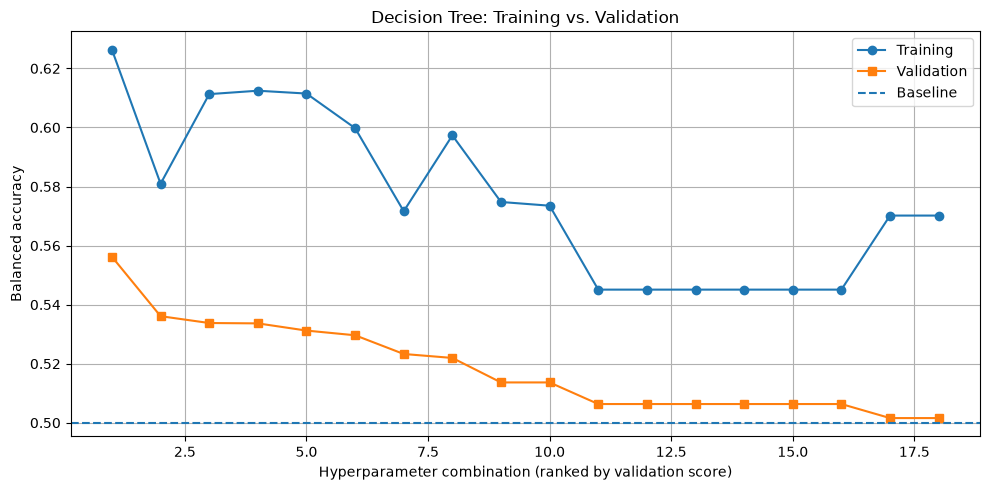

In [6]:
#compare training with validation performance
results = pd.DataFrame(grid.cv_results_)
results = results.sort_values("rank_test_score").reset_index(drop=True)

plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(results)+1),
    results["mean_train_score"],
    marker="o",
    label="Training",
)

plt.plot(
    range(1, len(results)+1),
    results["mean_test_score"],
    marker="s",
    label="Validation",
)

plt.axhline(0.5, linestyle="--", label="Baseline")
plt.xlabel("Hyperparameter combination (ranked by validation score)")
plt.ylabel("Balanced accuracy")
plt.title("Decision Tree: Training vs. Validation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
#save the best validaiton results
evaluation = evaluate(
    name="decision_tree",
    params=grid.best_params_,
    y_true=y_val,
    y_pred=best_pred,
    y_score =best_score,
    owner="pamela",
    split="val",
)
print(evaluation)

{'timestamp': '2026-11-19T00:55:20', 'owner': 'pamela', 'model': 'decision_tree', 'params': '{"classifier__criterion": "gini", "classifier__max_depth": 8, "classifier__min_samples_leaf": 5}', 'split': 'val', 'n': 305, 'accuracy': 0.6754098360655738, 'balanced_accuracy': 0.556219512195122, 'precision': 0.7007575757575758, 'recall': 0.9024390243902439, 'f1': 0.7889125799573561, 'roc_auc': 0.5444146341463415, 'tn': 21, 'fp': 79, 'fn': 20, 'tp': 185}


## Results + Analysis
The tuned Decision Tree received a validation balanced accuracy of approximately 55.62%, which outperformed the majority class baseline of 50% and untuned Decision Tree yielding 53.68%. There may be some overfitting due to the training balanced accuracy being higher than validation balanced accuracy cross the hyperparameter combinations. The modest improvement over baseline highlights the difficulty of predicting Supreme Court decisions using historical case characteristics despite the hyperparameter tuning improving performance.